STEP 0 : THE EMPLOYEE PROMOTION DATASET
   Experience      Education Performance      Training Attendance Promotion
0        High       Graduate   Excellent     Completed       Good       Yes
1        High       Graduate   Excellent     Completed       Good       Yes
2      Medium       Graduate   Excellent     Completed       Good       Yes
3        High   Postgraduate        Good     Completed       Good       Yes
4      Medium   Postgraduate        Good     Completed       Good       Yes
5        High       Graduate        Good     Completed  Excellent       Yes
6      Medium       Graduate        Good     Completed  Excellent       Yes
7        High   Postgraduate   Excellent     Completed       Good       Yes
8      Medium   Postgraduate   Excellent     Completed       Good       Yes
9         Low       Graduate     Average  NotCompleted       Poor        No
10        Low  Undergraduate        Good  NotCompleted       Poor        No
11     Medium  Undergraduate     Average  NotCom

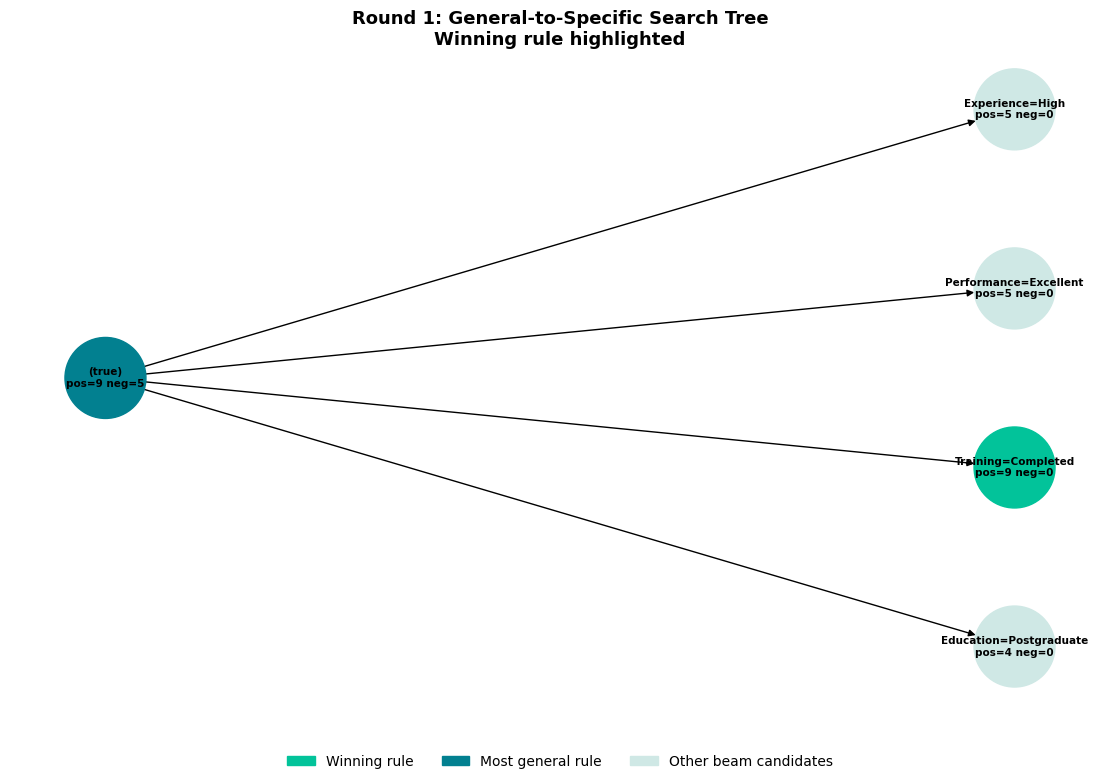

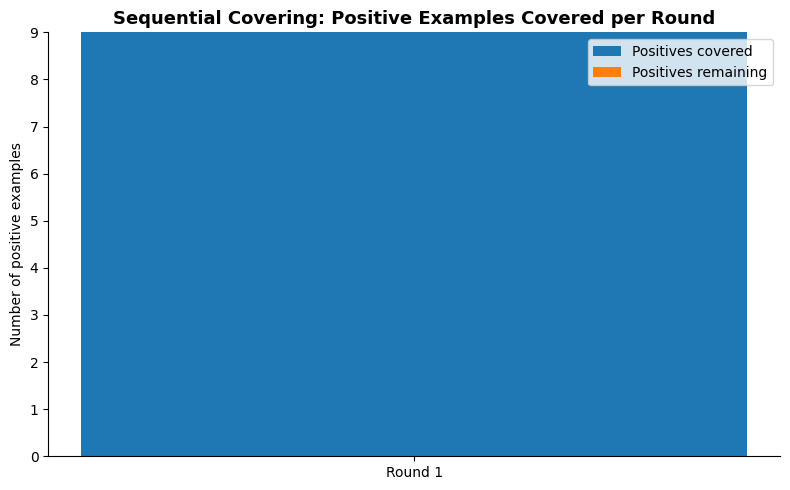

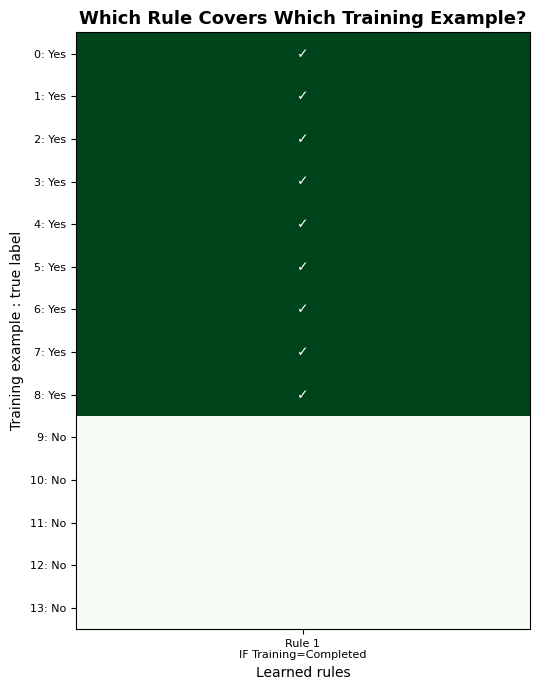

In [ ]:

# Sequential Covering Algorithm — Employee Promotion Dataset

!pip install networkx -q

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx


# DATASET
# Attributes:
# Experience, Education, Performance, Training, Attendance

# Target:
# Promotion = Yes / No

columns = [
    "Experience",
    "Education",
    "Performance",
    "Training",
    "Attendance",
    "Promotion"
]

data = [

    # ---- Positive examples ----
    ["High",   "Graduate", "Excellent", "Completed", "Good", "Yes"],
    ["High",   "Graduate", "Excellent", "Completed", "Good", "Yes"],
    ["Medium", "Graduate", "Excellent", "Completed", "Good", "Yes"],
    ["High",   "Postgraduate", "Good", "Completed", "Good", "Yes"],
    ["Medium", "Postgraduate", "Good", "Completed", "Good", "Yes"],
    ["High",   "Graduate", "Good", "Completed", "Excellent", "Yes"],

    # ---- More positive examples ----
    ["Medium", "Graduate", "Good", "Completed", "Excellent", "Yes"],
    ["High",   "Postgraduate", "Excellent", "Completed", "Good", "Yes"],
    ["Medium", "Postgraduate", "Excellent", "Completed", "Good", "Yes"],

    # ---- Negative examples ----
    ["Low",    "Graduate", "Average", "NotCompleted", "Poor", "No"],
    ["Low",    "Undergraduate", "Good", "NotCompleted", "Poor", "No"],
    ["Medium", "Undergraduate", "Average", "NotCompleted", "Good", "No"],
    ["Low",    "Graduate", "Good", "NotCompleted", "Average", "No"],
    ["Medium", "Graduate", "Average", "NotCompleted", "Poor", "No"],
]

df = pd.DataFrame(data, columns=columns)

TARGET_ATTR = "Promotion"
TARGET_VAL = "Yes"

ATTRIBUTES = [
    c for c in columns
    if c != TARGET_ATTR
]

# Domain (possible values) of every attribute
DOMAIN = {
    attr: sorted(df[attr].unique())
    for attr in ATTRIBUTES
}

# PRINT DATASET

def print_dataset():

    print("=" * 78)
    print("STEP 0 : THE EMPLOYEE PROMOTION DATASET")
    print("=" * 78)

    print(df.to_string(index=True))

    n_pos = (
        df[TARGET_ATTR] == TARGET_VAL
    ).sum()

    n_neg = (
        df[TARGET_ATTR] != TARGET_VAL
    ).sum()

    print(
        f"\nTotal examples: {len(df)}"
        f" | Positive (Yes): {n_pos}"
        f" | Negative (No): {n_neg}"
    )

    print()


# RULE REPRESENTATION & SCORING

def covers(rule, row):
    """
    Check whether an example satisfies
    every condition in the rule.
    """

    return all(
        row[attr] == val
        for attr, val in rule.items()
    )


def evaluate(rule, examples):
    """
    Return:
    positives covered,
    negatives covered,
    precision
    """

    covered = examples[
        examples.apply(
            lambda r: covers(rule, r),
            axis=1
        )
    ]

    pos = (
        covered[TARGET_ATTR] == TARGET_VAL
    ).sum()

    neg = (
        covered[TARGET_ATTR] != TARGET_VAL
    ).sum()

    precision = (
        pos / (pos + neg)
        if (pos + neg) > 0
        else 0.0
    )

    return pos, neg, precision


def rule_to_str(rule):

    if not rule:
        return "IF (true)"

    conds = " AND ".join(
        f"{a}={v}"
        for a, v in rule.items()
    )

    return f"IF {conds}"


# LEARN-ONE-RULE
# General-to-Specific BEAM SEARCH

def learn_one_rule(
    examples,
    beam_width=4,
    max_conditions=None
):

    """
    Performs a general-to-specific beam search.

    Starts with the empty rule and adds
    one attribute=value condition at a time.
    """

    if max_conditions is None:
        max_conditions = len(ATTRIBUTES)

    search_history = []

    # Depth 0
    # Most general rule

    beam = [{}]

    depth0_pos, depth0_neg, depth0_prec = evaluate(
        {},
        examples
    )

    search_history.append({
        "depth": 0,

        "candidates": [
            (
                {},
                depth0_pos,
                depth0_neg,
                depth0_prec,
                None
            )
        ],

        "beam": [{}]
    })

    best_rule = {}

    best_pos = depth0_pos
    best_neg = depth0_neg
    best_prec = depth0_prec


    # Generate increasingly specific rules

    for depth in range(
        1,
        max_conditions + 1
    ):

        candidates = []

        for parent in beam:

            used_attrs = set(
                parent.keys()
            )

            for attr in ATTRIBUTES:

                if attr in used_attrs:
                    continue

                for val in DOMAIN[attr]:

                    child = dict(parent)

                    child[attr] = val

                    pos, neg, prec = evaluate(
                        child,
                        examples
                    )

                    # Ignore rules covering no positives
                    if pos == 0:
                        continue

                    candidates.append(
                        (
                            child,
                            pos,
                            neg,
                            prec,
                            parent
                        )
                    )


        if not candidates:
            break


        # Rank candidates

        # Priority:
        # 1. No negative examples
        # 2. Higher precision
        # 3. Higher positive coverage

        candidates.sort(
            key=lambda c: (
                c[2] == 0,
                c[3],
                c[1]
            ),
            reverse=True
        )


        # Keep top beam_width rules

        new_beam = []

        seen = set()

        for (
            child,
            pos,
            neg,
            prec,
            parent
        ) in candidates:

            key = frozenset(
                child.items()
            )

            if key not in seen:

                seen.add(key)

                new_beam.append(
                    child
                )

            if len(new_beam) >= beam_width:
                break


        beam = new_beam


        search_history.append({
            "depth": depth,
            "candidates": candidates,
            "beam": beam
        })

        # Check for pure rule

        pure_candidates = [
            c
            for c in candidates
            if c[2] == 0
        ]


        if pure_candidates:

            top = pure_candidates[0]

            (
                best_rule,
                best_pos,
                best_neg,
                best_prec
            ) = (
                top[0],
                top[1],
                top[2],
                top[3]
            )

            break

        else:

            top = candidates[0]

            if (
                top[2] == 0,
                top[3],
                top[1]
            ) > (
                best_neg == 0,
                best_prec,
                best_pos
            ):

                (
                    best_rule,
                    best_pos,
                    best_neg,
                    best_prec
                ) = (
                    top[0],
                    top[1],
                    top[2],
                    top[3]
                )


    return (
        best_rule,
        best_pos,
        best_neg,
        best_prec,
        search_history
    )


# SEQUENTIAL COVERING

def sequential_covering(
    beam_width=4
):

    working = df.copy()

    rules = []

    round_logs = []

    round_num = 1


    # Continue until all positive examples
    # have been covered

    while (
        working[TARGET_ATTR] == TARGET_VAL
    ).sum() > 0:


        # Learn one rule

        (
            rule,
            pos,
            neg,
            prec,
            history
        ) = learn_one_rule(
            working,
            beam_width=beam_width
        )

        # Find examples covered by rule

        covered_mask = working.apply(
            lambda r: covers(rule, r),
            axis=1
        )

        covered_examples = working[
            covered_mask
        ]


        covered_positive_idx = (
            covered_examples[
                covered_examples[TARGET_ATTR]
                == TARGET_VAL
            ].index.tolist()
        )


        # Print round information

        print(
            f"--- Round {round_num} ---"
        )

        print(
            "Remaining positives before this round :",
            (
                working[TARGET_ATTR]
                == TARGET_VAL
            ).sum()
        )

        print(
            "Learned rule :",
            rule_to_str(rule),
            "THEN",
            TARGET_ATTR,
            "=",
            TARGET_VAL
        )

        print(
            "Covers :",
            pos,
            "positive(s),",
            neg,
            "negative(s)"
        )

        print(
            "Positive example indices covered :",
            covered_positive_idx
        )

        print()


        # Store rule

        rules.append(rule)

        round_logs.append({

            "round": round_num,

            "rule": rule,

            "pos_covered": pos,

            "neg_covered": neg,

            "covered_positive_idx":
                covered_positive_idx,

            "history": history,

            "remaining_pos_before":
                (
                    working[TARGET_ATTR]
                    == TARGET_VAL
                ).sum()
        })


        # Remove covered positive examples

        working = working.drop(
            index=covered_positive_idx
        )

        round_num += 1


        # Safety check

        if pos == 0:

            print(
                "No further progress possible."
            )

            break


    return rules, round_logs



# GRAPH:
# SEARCH TREE PER ROUND

def plot_search_tree(
    history,
    winning_rule,
    round_num
):

    G = nx.DiGraph()

    labels = {}

    node_colors = []

    node_id_of_rule = {}


    def node_id(rule):

        key = frozenset(
            rule.items()
        )

        if key not in node_id_of_rule:

            node_id_of_rule[key] = (
                f"n{len(node_id_of_rule)}"
            )

        return node_id_of_rule[key]


    # Root

    root_pos, root_neg, root_prec = (
        history[0]["candidates"][0][1:4]
    )

    root_id = node_id({})

    G.add_node(root_id)

    labels[root_id] = (
        f"(true)\n"
        f"pos={root_pos} "
        f"neg={root_neg}"
    )


    winning_key = frozenset(
        winning_rule.items()
    )


    # Keep nodes appearing in beam

    kept_keys = set()

    for level in history:

        for r in level["beam"]:

            kept_keys.add(
                frozenset(r.items())
            )

    kept_keys.add(winning_key)


    # Add tree edges

    for level in history[1:]:

        for (
            child,
            pos,
            neg,
            prec,
            parent
        ) in level["candidates"]:

            key = frozenset(
                child.items()
            )

            if key not in kept_keys:
                continue

            cid = node_id(child)

            pid = node_id(parent)


            if not G.has_node(cid):

                G.add_node(cid)

                label = " ∧ ".join(
                    f"{a}={v}"
                    for a, v in child.items()
                )

                labels[cid] = (
                    f"{label}\n"
                    f"pos={pos} "
                    f"neg={neg}"
                )


            G.add_edge(
                pid,
                cid
            )


    # Assign layers

    for layer, nodes in enumerate(
        nx.bfs_layers(
            G,
            root_id
        )
    ):

        for n in nodes:
            G.nodes[n]["layer"] = layer


    pos_layout = nx.multipartite_layout(
        G,
        subset_key="layer"
    )


    # Node colors

    for n in G.nodes():

        key = None

        for k, v in node_id_of_rule.items():

            if v == n:
                key = k
                break


        if key == winning_key:

            node_colors.append(
                "#02C39A"
            )

        elif n == root_id:

            node_colors.append(
                "#028090"
            )

        else:

            node_colors.append(
                "#CFE8E5"
            )


    # Draw tree

    plt.figure(
        figsize=(11, 6.5)
    )

    nx.draw(
        G,
        pos_layout,
        labels=labels,
        with_labels=True,
        node_color=node_colors,
        node_size=3400,
        font_size=7.5,
        font_weight="bold",
        arrows=True
    )

    plt.title(
        f"Round {round_num}: "
        "General-to-Specific Search Tree\n"
        "Winning rule highlighted",
        fontsize=13,
        fontweight="bold"
    )

    winner_patch = mpatches.Patch(
        color="#02C39A",
        label="Winning rule"
    )

    root_patch = mpatches.Patch(
        color="#028090",
        label="Most general rule"
    )

    other_patch = mpatches.Patch(
        color="#CFE8E5",
        label="Other beam candidates"
    )

    plt.legend(
        handles=[
            winner_patch,
            root_patch,
            other_patch
        ],
        loc="lower center",
        bbox_to_anchor=(0.5, -0.12),
        ncol=3,
        frameon=False
    )

    plt.show()


# GRAPH:
# COVERAGE BAR CHART

def plot_coverage_bar(
    round_logs
):

    rounds = [
        f"Round {rl['round']}"
        for rl in round_logs
    ]

    covered = [
        rl["pos_covered"]
        for rl in round_logs
    ]


    remaining_after = []

    total_pos = (
        df[TARGET_ATTR]
        == TARGET_VAL
    ).sum()

    running = total_pos


    for rl in round_logs:

        running -= rl["pos_covered"]

        remaining_after.append(
            running
        )


    x = range(
        len(rounds)
    )


    fig, ax = plt.subplots(
        figsize=(8, 5)
    )


    ax.bar(
        x,
        covered,
        label="Positives covered"
    )


    ax.bar(
        x,
        remaining_after,
        bottom=covered,
        label="Positives remaining"
    )


    ax.set_xticks(
        list(x)
    )

    ax.set_xticklabels(
        rounds
    )

    ax.set_ylabel(
        "Number of positive examples"
    )

    ax.set_title(
        "Sequential Covering: "
        "Positive Examples Covered per Round",
        fontsize=13,
        fontweight="bold"
    )

    ax.legend()

    ax.spines[
        ["top", "right"]
    ].set_visible(False)

    plt.tight_layout()

    plt.show()

# GRAPH:
# FINAL COVERAGE HEATMAP

def plot_coverage_heatmap(
    rules
):

    n = len(df)

    m = len(rules)


    matrix = [

        [
            1 if covers(
                rule,
                df.loc[i]
            )
            else 0

            for rule in rules
        ]

        for i in range(n)
    ]


    fig, ax = plt.subplots(
        figsize=(4.5 + m, 7)
    )


    ax.imshow(
        matrix,
        cmap="Greens",
        aspect="auto",
        vmin=0,
        vmax=1
    )


    ax.set_xticks(
        range(m)
    )

    ax.set_xticklabels(
        [
            f"Rule {i + 1}\n"
            f"{rule_to_str(r)}"

            for i, r
            in enumerate(rules)
        ],
        fontsize=8
    )


    ax.set_yticks(
        range(n)
    )


    row_labels = [

        f"{i}: "
        f"{df.loc[i, TARGET_ATTR]}"

        for i in range(n)
    ]


    ax.set_yticklabels(
        row_labels,
        fontsize=8
    )


    # Add check marks

    for i in range(n):

        for j in range(m):

            if matrix[i][j]:

                ax.text(
                    j,
                    i,
                    "✓",
                    ha="center",
                    va="center",
                    color="white",
                    fontweight="bold"
                )


    ax.set_title(
        "Which Rule Covers Which Training Example?",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Learned rules"
    )

    ax.set_ylabel(
        "Training example : true label"
    )

    plt.tight_layout()

    plt.show()


# MAIN

print_dataset()


print("=" * 78)
print("STEP 1 : RUNNING SEQUENTIAL COVERING")
print("=" * 78)


rules, round_logs = sequential_covering(
    beam_width=4
)


# FINAL LEARNED RULE SET

print("=" * 78)
print("FINAL LEARNED RULE SET")
print("=" * 78)


for i, r in enumerate(
    rules,
    start=1
):

    print(
        f"Rule {i}: "
        f"{rule_to_str(r)} "
        f"THEN "
        f"{TARGET_ATTR} = {TARGET_VAL}"
    )


print()


# GENERATE GRAPHS

print("=" * 78)
print("STEP 2 : GENERATING GRAPHS")
print("=" * 78)


for rl in round_logs:

    plot_search_tree(
        rl["history"],
        rl["rule"],
        rl["round"]
    )


plot_coverage_bar(
    round_logs
)


plot_coverage_heatmap(
    rules
)